### E3SM Map
Map the output of the E3SM Error

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [2]:
# Load the CSV data
df = pd.read_csv('e3sm_snotel_comparison.csv')
df.head()

,site,snotel_name,latitude,longitude,elevation,rmse,bias,mean_swe,n_observations,n_years
0,Forestdale_Creek,Forestdale Creek,38.682311,-119.960653,2445.1,212.4,-125.7,283.9,183,15.25
1,Horse_Meadow,Horse Meadow,38.836411,-119.888317,2623.1,83.0,-42.2,122.7,123,10.25
2,Burnside_Lake,Burnside Lake,38.719328,-119.895194,2491.7,63.9,-31.4,200.0,195,16.25
3,Summit_Meadow,Summit Meadow,38.397400,-119.536217,2843.8,55.7,-31.8,100.5,96,8.00
4,Carson_Pass,Carson Pass,38.692667,-120.002128,2547.7,136.2,-74.7,251.3,159,13.25


In [3]:
# Remove sites where 'output_years' < 5
df = df[df['n_years'] >= 5]
len(df)

757

In [4]:
# Calculate normalized bias and rmse
df['nbias'] = df['bias'] / df['mean_swe']
df['nrmse'] = df['rmse'] / df['mean_swe']
print('Mean Normalized Bias:', df['nbias'].mean())
print('Mean Normalized RMSE:', df['nrmse'].mean())

Mean Normalized Bias: -0.3833776074186798
Mean Normalized RMSE: 1.0988491286938766


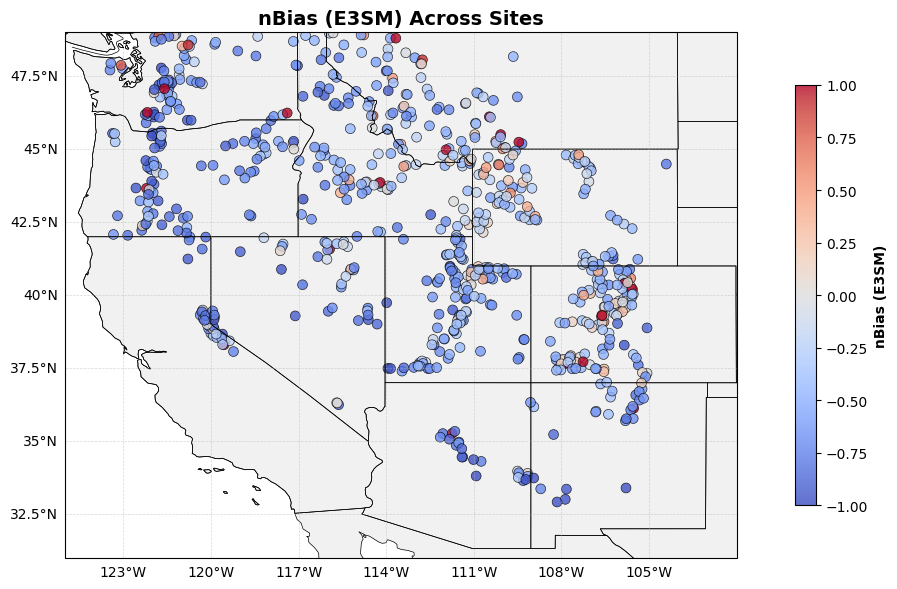

In [5]:
# Plot of nBias for presentation purposes
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(df['longitude'], df['latitude'],
                     c=df['nbias'],
                     s=50,
                     alpha=0.8,
                     cmap='coolwarm',
                     vmin=-1,
                     vmax=1,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label('nBias (E3SM)', fontsize=10, fontweight='bold')
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
ax.set_title('nBias (E3SM) Across Sites', fontsize=14, fontweight='bold')
plt.tight_layout()

### Elevation

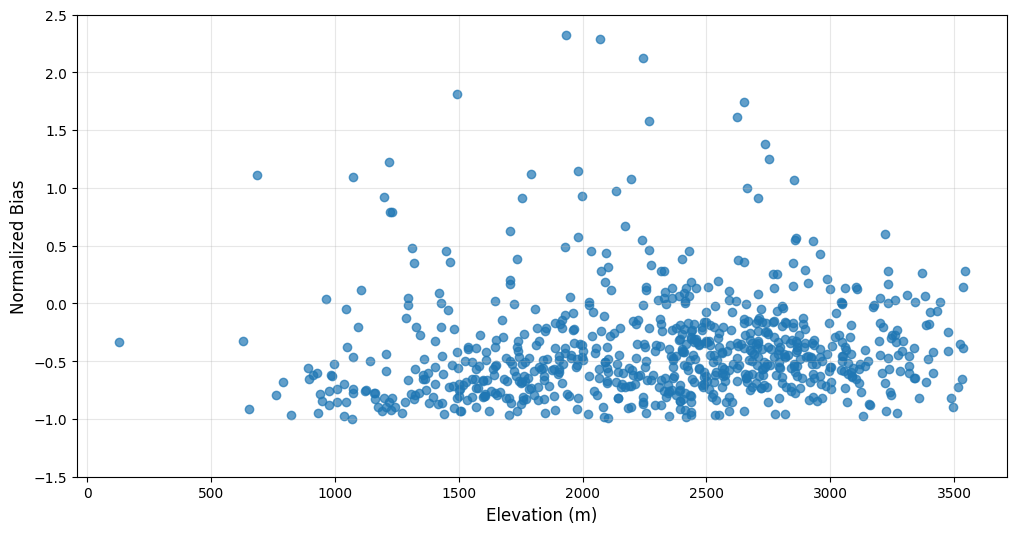

In [7]:
# Visualize the normalized bias as a function of elevation
plt.figure(figsize=(12, 6))
plt.scatter(df['elevation'], df['nbias'], alpha=0.7)

#Limit range of y-axis to < 2.5
plt.ylim(-1.5, 2.5)

plt.xlabel('Elevation (m)', fontsize=12)
plt.ylabel('Normalized Bias', fontsize=12)
#plt.title(f'{alias_name.get(column_of_interest, column_of_interest)} vs Elevation', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)